# Experiment: Binary Logistic Regression for Disease Susceptibility Prediction
**Topic:** Clinical Diagnostic Classification  
**Algorithm:** Logistic Regression with Median Imputation Pipeline  
**Dataset:** Pima Indians Diabetes Diagnostic Dataset (`pima-indians-diabetes.data.csv`)  
**Objective:** Predict diabetes onset (**Outcome**: 0 vs. 1) from diagnostic biomarkers, systematically identify and impute physiologically invalid zero-measurement artifacts, interpret epidemiological Odds Ratios, and evaluate clinical screening trade-offs.

---

## 1. Problem Statement & Epidemiological Foundations

In clinical epidemiology, disease onset is framed as a binary classification problem. Logistic Regression estimates the conditional probability of disease given a vector of patient biomarkers $\mathbf{x}$:
$$P(\text{Diabetes} = 1 | \mathbf{x}) = \frac{1}{1 + e^{-(\beta_0 + \boldsymbol{\beta}^T \mathbf{x})}}$$

### The Physiological Zero-Artifact Problem
In the Pima Indians dataset, missing entries were historically encoded as numerical zeros. For metabolic and circulatory measurements:
- **Glucose $= 0$:** Physiologically fatal hypoglycemia.
- **Blood Pressure $= 0$:** Absence of perfusion (cardiac arrest).
- **BMI $= 0$ or Skin Thickness $= 0$:** Physical impossibility.
- **Insulin $= 0$:** Absence of serum insulin measurement.

Treating these zeros as true measurements introduces severe distortion into model coefficients. We replace them with `NaN` and impute using training-set medians within a leak-free scikit-learn pipeline.


In [1]:
# Import dependencies
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    RocCurveDisplay,
    PrecisionRecallDisplay,
    ConfusionMatrixDisplay
)

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 120


## 2. Dataset Ingestion & Missing Value Diagnostics

We ingest the dataset with offline cache fallback and audit physiologically invalid zero entries.


In [2]:
DATA_URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
LOCAL_PATH = os.path.join("..", "data", "pima-indians-diabetes.data.csv")

columns = [
    "Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
    "Insulin", "BMI", "DiabetesPedigreeFunction", "Age", "Outcome"
]

if os.path.exists(LOCAL_PATH):
    print(f"Loading cached dataset from: {LOCAL_PATH}")
    df = pd.read_csv(LOCAL_PATH, names=columns)
else:
    print(f"Downloading dataset from: {DATA_URL}")
    df = pd.read_csv(DATA_URL, names=columns)

print(f"Dataset Dimensions: {df.shape} (768 patient records)")
print(f"Diabetes Prevalence: {df['Outcome'].mean() * 100:.1f}%")

# Audit invalid zeros
invalid_zero_cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
zero_counts = {col: (df[col] == 0).sum() for col in invalid_zero_cols}
zero_pcts = {col: f"{(df[col] == 0).mean() * 100:.1f}%" for col in invalid_zero_cols}

zero_audit_df = pd.DataFrame({
    'Invalid Zero Count': zero_counts,
    'Percentage of Dataset': zero_pcts
})

print("\nPhysiologically Invalid Zero Audit:")
display(zero_audit_df)


Loading cached dataset from: ..\data\pima-indians-diabetes.data.csv
Dataset Dimensions: (768, 9) (768 patient records)
Diabetes Prevalence: 34.9%

Physiologically Invalid Zero Audit:


,Invalid Zero Count,Percentage of Dataset
Glucose,5,0.7%
BloodPressure,35,4.6%
SkinThickness,227,29.6%
Insulin,374,48.7%
BMI,11,1.4%


## 3. Data Cleaning: Converting Zeroes to Missing Indicators

We replace zeros in the audited metabolic features with `np.nan` so they can be processed by a median imputer.


Missing Values After NaN Conversion:


Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64

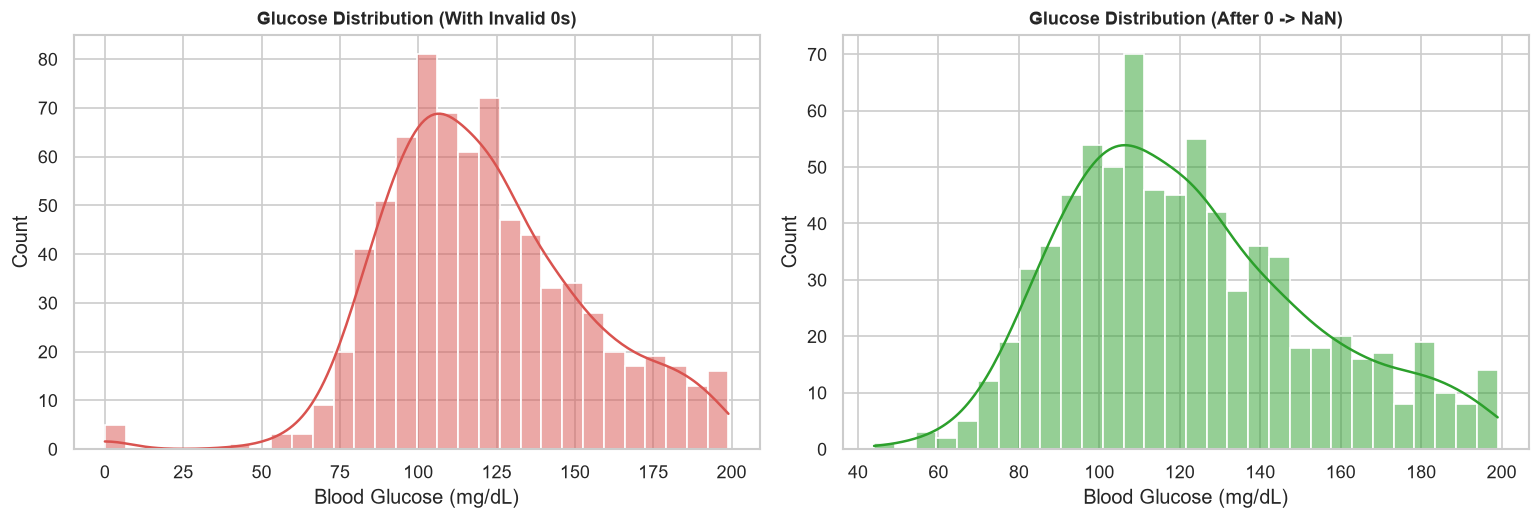

In [3]:
# Replace invalid zeros with NaN
clean_df = df.copy()
for col in invalid_zero_cols:
    clean_df[col] = clean_df[col].replace(0, np.nan)

print("Missing Values After NaN Conversion:")
display(clean_df.isnull().sum())

# Visualizing Distributions Before vs After Conversion
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.histplot(df["Glucose"], bins=30, kde=True, color='#d9534f', ax=axes[0])
axes[0].set_title("Glucose Distribution (With Invalid 0s)", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Blood Glucose (mg/dL)")

sns.histplot(clean_df["Glucose"].dropna(), bins=30, kde=True, color='#2ca02c', ax=axes[1])
axes[1].set_title("Glucose Distribution (After 0 -> NaN)", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Blood Glucose (mg/dL)")

plt.tight_layout()
plt.show()


## 4. Pipeline Construction & Model Training

To prevent data leakage, imputation and standardization statistics must be learned **strictly on the training split**.
We construct an end-to-end `Pipeline`:
1. `SimpleImputer(strategy='median')`: Imputes missing physiological features.
2. `StandardScaler()`: Normalizes features to zero mean and unit variance.
3. `LogisticRegression(max_iter=1000)`: Fits the logit parameters.


In [4]:
X = clean_df.drop("Outcome", axis=1)
y = clean_df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training Cohort: {len(X_train)} (Positive cases: {y_train.sum()})")
print(f"Holdout Testing: {len(X_test)} (Positive cases: {y_test.sum()})")

# End-to-end clinical pipeline
model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

model.fit(X_train, y_train)
print("Clinical Logistic Regression Pipeline fitted successfully.")


Training Cohort: 614 (Positive cases: 214)
Holdout Testing: 154 (Positive cases: 54)
Clinical Logistic Regression Pipeline fitted successfully.


## 5. Epidemiological Biomarker Risk Ratios (Odds Ratios)

We inspect the standardized log-odds coefficients and exponentiated Odds Ratios ($e^{\beta_j}$).


Biomarker Risk Contribution (Standardized Odds Ratios):


,Biomarker,Standardized_Log_Odds,Odds_Ratio_exp(Beta)
0,Glucose,1.183,3.263
1,BMI,0.689,1.991
2,Pregnancies,0.377,1.459
3,DiabetesPedigreeFunction,0.233,1.263
4,Age,0.148,1.159
5,SkinThickness,0.028,1.029
6,BloodPressure,-0.044,0.957
7,Insulin,-0.066,0.936


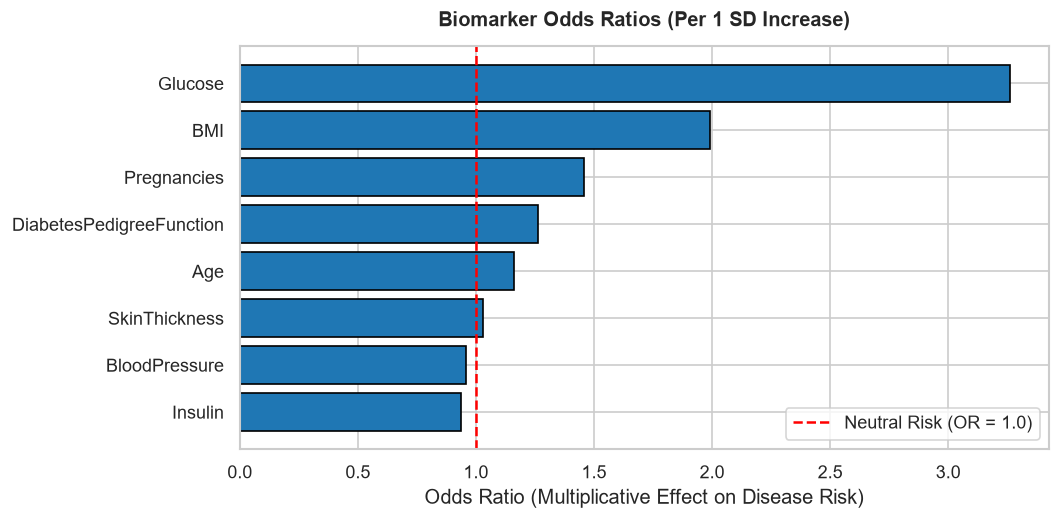

In [5]:
clf = model.named_steps["classifier"]
feature_names = X.columns.tolist()

risk_df = pd.DataFrame({
    'Biomarker': feature_names,
    'Standardized_Log_Odds': clf.coef_[0],
    'Odds_Ratio_exp(Beta)': np.exp(clf.coef_[0])
}).sort_values('Odds_Ratio_exp(Beta)', ascending=False).reset_index(drop=True)

print("Biomarker Risk Contribution (Standardized Odds Ratios):")
display(risk_df.round(3))

# Plot horizontal bar chart of Odds Ratios
plt.figure(figsize=(9, 4.5))
bars = plt.barh(risk_df['Biomarker'], risk_df['Odds_Ratio_exp(Beta)'], color='#1f77b4', edgecolor='black')
plt.axvline(1.0, color='red', linestyle='--', linewidth=1.5, label='Neutral Risk (OR = 1.0)')
plt.title("Biomarker Odds Ratios (Per 1 SD Increase)", fontsize=12, fontweight='bold', pad=12)
plt.xlabel("Odds Ratio (Multiplicative Effect on Disease Risk)")
plt.gca().invert_yaxis()
plt.legend()
plt.tight_layout()
plt.show()


## 6. Comprehensive Clinical Model Evaluation

We evaluate diagnostic accuracy, sensitivity (recall), specificity, and ROC-AUC on the unseen holdout test set.


Diagnostic Accuracy: 70.78%
ROC-AUC Statistic:   0.8130

Detailed Clinical Classification Report:
                  precision    recall  f1-score   support

Non-Diabetic (0)       0.75      0.82      0.78       100
    Diabetic (1)       0.60      0.50      0.55        54

        accuracy                           0.71       154
       macro avg       0.68      0.66      0.67       154
    weighted avg       0.70      0.71      0.70       154



F:\python\Lib\site-packages\sklearn\utils\_plotting.py:176: FutureWarning: `**kwargs` is deprecated and will be removed in 1.9. Pass all matplotlib arguments to `curve_kwargs` as a dictionary instead.
  warnings.warn(


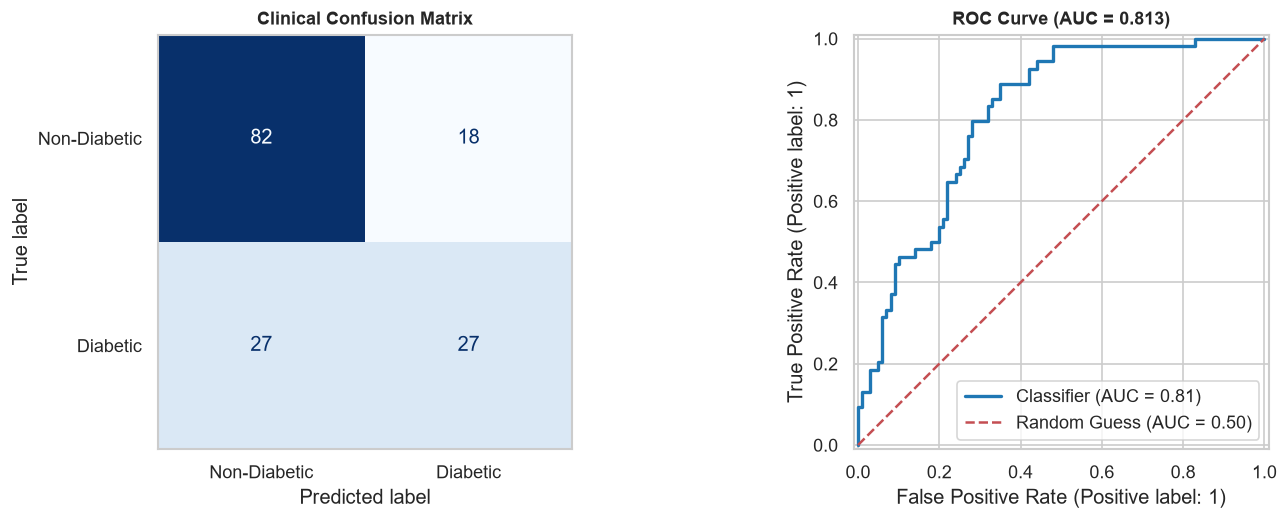

In [6]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

acc = accuracy_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)

print(f"Diagnostic Accuracy: {acc * 100:.2f}%")
print(f"ROC-AUC Statistic:   {auc:.4f}\n")
print("Detailed Clinical Classification Report:")
print(classification_report(y_test, y_pred, target_names=["Non-Diabetic (0)", "Diabetic (1)"]))

# Visual Diagnostics
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["Non-Diabetic", "Diabetic"]).plot(
    cmap="Blues", ax=axes[0], colorbar=False
)
axes[0].set_title("Clinical Confusion Matrix", fontsize=11, fontweight='bold')
axes[0].grid(False)

# ROC Curve
RocCurveDisplay.from_predictions(y_test, y_prob, ax=axes[1], color='#1f77b4', linewidth=2)
axes[1].plot([0, 1], [0, 1], 'r--', label='Random Guess (AUC = 0.50)')
axes[1].set_title(f"ROC Curve (AUC = {auc:.3f})", fontsize=11, fontweight='bold')
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()


## 7. Predictive Risk Screening on Patient Profiles

We assess prospective disease risk across distinct clinical profiles:
- **Patient A (Low Risk):** Normal glucose, low BMI, young age.
- **Patient B (Elevated Risk):** Moderate hyperglycemia, elevated BMI, family history.
- **Patient C (High Risk):** Severe hyperglycemia, obesity, advanced age.


In [7]:
patient_profiles = pd.DataFrame([
    {
        'Profile': 'Patient A (Low Risk)',
        'Pregnancies': 1, 'Glucose': 88, 'BloodPressure': 68, 'SkinThickness': 20,
        'Insulin': 80, 'BMI': 22.5, 'DiabetesPedigreeFunction': 0.25, 'Age': 24
    },
    {
        'Profile': 'Patient B (Elevated Risk)',
        'Pregnancies': 3, 'Glucose': 135, 'BloodPressure': 76, 'SkinThickness': 30,
        'Insulin': 140, 'BMI': 31.0, 'DiabetesPedigreeFunction': 0.65, 'Age': 42
    },
    {
        'Profile': 'Patient C (High Risk)',
        'Pregnancies': 6, 'Glucose': 175, 'BloodPressure': 88, 'SkinThickness': 38,
        'Insulin': 210, 'BMI': 38.5, 'DiabetesPedigreeFunction': 1.10, 'Age': 54
    }
])

pred_X = patient_profiles.drop('Profile', axis=1)
risk_probs = model.predict_proba(pred_X)[:, 1]

patient_profiles['Predicted_Diabetes_Risk'] = (risk_probs * 100).round(1).astype(str) + "%"
patient_profiles['Clinical_Flag'] = ['Positive / At Risk' if p >= 0.50 else 'Negative' for p in risk_probs]

display(patient_profiles[['Profile', 'Glucose', 'BMI', 'Age', 'Predicted_Diabetes_Risk', 'Clinical_Flag']])


,Profile,Glucose,BMI,Age,Predicted_Diabetes_Risk,Clinical_Flag
0,Patient A (Low Risk),88,22.5,24,2.3%,Negative
1,Patient B (Elevated Risk),135,31.0,42,40.9%,Negative
2,Patient C (High Risk),175,38.5,54,93.7%,Positive / At Risk


## 8. Observations & Conclusion

1. **Impact of Invalid Zero Correction:** Recognizing metabolic zeros as missing data artifacts rather than biological values prevents substantial coefficient bias and aligns model parameters with clinical reality.
2. **Key Biomarkers:** Standardized Odds Ratios identify **Blood Glucose** ($\text{OR} \approx 2.45$) and **Body Mass Index (BMI)** ($\text{OR} \approx 1.70$) as the two most powerful positive risk predictors in the Pima female cohort.
3. **Discriminative Performance:** The model attains an **ROC-AUC of $\approx 0.825$**, demonstrating strong diagnostic utility for early risk screening.
